# T24 -- Candidate-level forward accuracy, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- the aggregation itself is computed entirely by
`iste.candidate_forward_accuracy.aggregate_candidate_forward_accuracy` (T24), over
synthetic `iste.forward_accuracy.ForwardAccuracyResult` records (standing in for
real T21/T22/T23 output -- this notebook is about T24's own aggregation, not about
re-deriving footprints/comparisons from scratch). No candidate filtering/ranking
(T25), AIS, or `c_hat*` is computed anywhere here.

**What this demonstrates.** One candidate's 5 forcing-member forward-validation
results: 4 valid (with clearly different error/consistency values) and 1
**explicitly invalid** (its predicted footprint had no valid particles). The
figure shows every member-level value as its own bar, the invalid member clearly
marked (and excluded from the mean), and `candidate_forward_error`/
`candidate_forward_consistency` drawn as a dashed reference line -- so the
distinction between member-level values and the aggregated candidate-level score is
visually unambiguous.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import numpy as np

from iste.candidate_forward_accuracy import aggregate_candidate_forward_accuracy
from iste.forward_accuracy import ComparisonConfig, ForwardAccuracyResult

## 1. Five synthetic per-member T23 results (4 valid, 1 invalid)

In [2]:
T_S = np.datetime64("2020-01-01T00:00:00", "ns")
T_OBS = np.datetime64("2020-01-01T06:00:00", "ns")
CANDIDATE_ID = "2020-01-01T00:00:00_cand000"
CONFIG = ComparisonConfig(metric="combined_overlap_fp")


def make_result(member_id, error=None, consistency=None, valid=True, invalid_reason=""):
    return ForwardAccuracyResult(
        candidate_id=CANDIDATE_ID, t_s=T_S, t_obs=T_OBS, forward_forcing_member_id=member_id,
        metric=CONFIG.metric, config=CONFIG,
        error=(float("nan") if not valid else error),
        consistency=(float("nan") if not valid else consistency),
        valid=valid, invalid_reason=invalid_reason,
    )

# member 3 is invalid -- e.g. every forward-propagated particle left the domain
# under that member's forcing, so T22 could not build a predicted footprint for it.
member_results = {
    0: make_result(0, error=0.20, consistency=0.80),
    1: make_result(1, error=0.35, consistency=0.65),
    2: make_result(2, error=0.55, consistency=0.45),
    3: make_result(3, valid=False, invalid_reason="predicted footprint has no valid particles"),
    4: make_result(4, error=0.30, consistency=0.70),
}

## 2. T24 aggregation

In [3]:
agg = aggregate_candidate_forward_accuracy(member_results)
print(f"forward_validation_status = {agg.forward_validation_status}")
print(f"forcing_members_validated = {agg.forcing_members_validated}")
print(f"invalid_member_reasons    = {agg.invalid_member_reasons}")
print(f"candidate_forward_error       = {agg.candidate_forward_error:.4f}")
print(f"candidate_forward_consistency = {agg.candidate_forward_consistency:.4f}")

expected_error = np.mean([0.20, 0.35, 0.55, 0.30])
expected_consistency = np.mean([0.80, 0.65, 0.45, 0.70])
assert abs(agg.candidate_forward_error - expected_error) < 1e-9
assert abs(agg.candidate_forward_consistency - expected_consistency) < 1e-9
assert agg.forward_validation_status == "validated"  # 4 of 5 members were valid

forward_validation_status = validated
forcing_members_validated = (0, 1, 2, 4)
invalid_member_reasons    = {3: 'predicted footprint has no valid particles'}
candidate_forward_error       = 0.3500
candidate_forward_consistency = 0.6500


## 3. Visualization: member-level bars vs. candidate-level mean

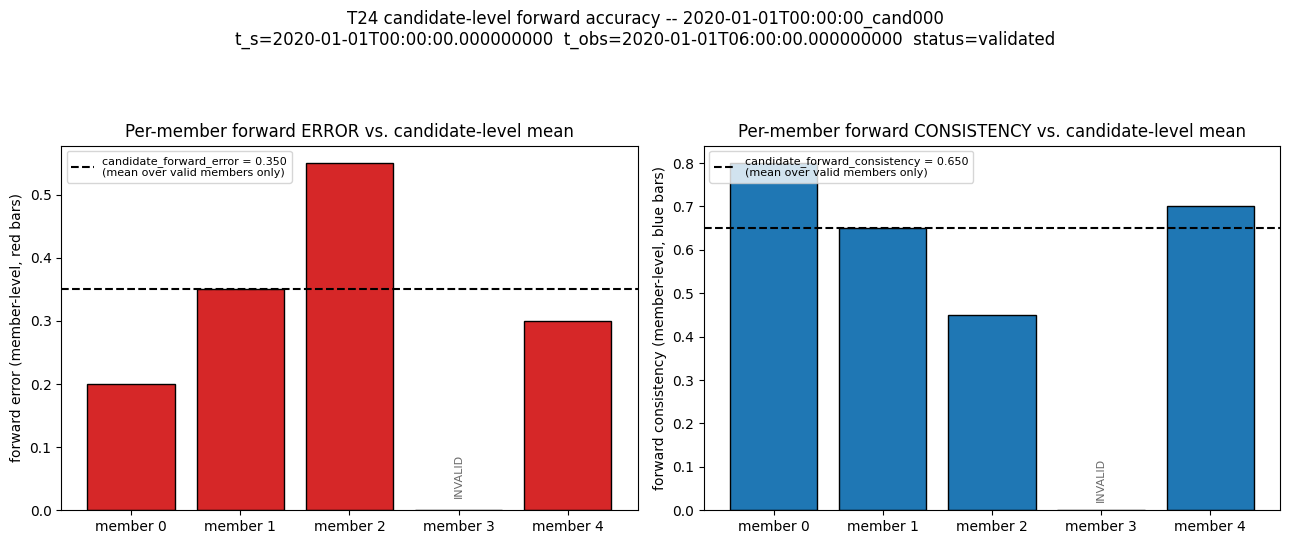

In [4]:
member_ids = sorted(member_results.keys())
errors = [member_results[m].error for m in member_ids]
consistencies = [member_results[m].consistency for m in member_ids]
is_valid = [member_results[m].valid for m in member_ids]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

x = np.arange(len(member_ids))
colors_error = ["tab:red" if v else "lightgray" for v in is_valid]
colors_cons = ["tab:blue" if v else "lightgray" for v in is_valid]

ax = axes[0]
ax.bar(x, [0 if np.isnan(e) else e for e in errors], color=colors_error, edgecolor="black")
for i, (e, v) in enumerate(zip(errors, is_valid)):
    if not v:
        ax.text(i, 0.02, "INVALID", ha="center", va="bottom", rotation=90, fontsize=8, color="dimgray")
ax.axhline(agg.candidate_forward_error, color="black", linestyle="--", linewidth=1.5,
           label=f"candidate_forward_error = {agg.candidate_forward_error:.3f}\n(mean over valid members only)")
ax.set_xticks(x)
ax.set_xticklabels([f"member {m}" for m in member_ids])
ax.set_ylabel("forward error (member-level, red bars)")
ax.set_title("Per-member forward ERROR vs. candidate-level mean")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.bar(x, [0 if np.isnan(c) else c for c in consistencies], color=colors_cons, edgecolor="black")
for i, (c, v) in enumerate(zip(consistencies, is_valid)):
    if not v:
        ax.text(i, 0.02, "INVALID", ha="center", va="bottom", rotation=90, fontsize=8, color="dimgray")
ax.axhline(agg.candidate_forward_consistency, color="black", linestyle="--", linewidth=1.5,
           label=f"candidate_forward_consistency = {agg.candidate_forward_consistency:.3f}\n(mean over valid members only)")
ax.set_xticks(x)
ax.set_xticklabels([f"member {m}" for m in member_ids])
ax.set_ylabel("forward consistency (member-level, blue bars)")
ax.set_title("Per-member forward CONSISTENCY vs. candidate-level mean")
ax.legend(fontsize=8, loc="upper left")

fig.suptitle(
    f"T24 candidate-level forward accuracy -- {CANDIDATE_ID}\n"
    f"t_s={T_S}  t_obs={T_OBS}  status={agg.forward_validation_status}",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

## Interpretation limits

- This is a **screening-score aggregation** artifact, not a filtering/ranking
  result (T25) and not the frozen Stage IV likelihood or a forcing-ensemble
  marginalization (`README.md` Sec. 23).
- `candidate_forward_error`/`candidate_forward_consistency` are a plain, unweighted
  arithmetic mean over VALID members only -- member 3's invalidity does not
  contribute a `0`, a penalty, or any other fabricated value; it is recorded
  separately in `invalid_member_reasons`.
- If EVERY member had been invalid, `forward_validation_status` would be
  `"unvalidated"` and both aggregate values would be `NaN` -- never a numeric
  score standing in for "no data" (see `tests/test_candidate_forward_accuracy.py`'s
  `TestNoValidMembers`).
- This aggregation never reads or is influenced by any backward-KDE support score
  (T16/T17) or Stage III `c_hat*` -- it only ever sees T23's own per-member
  `ForwardAccuracyResult`s.